# Sticker color classification

Classification only: sticker polygons are the CVAT annotations, no detector. Methods A, B, B+, B++
C, C+, C++ in several color spaces, on all annotated cubes. Runs locally after `make data`
(`dvc pull` is enough).

In [ ]:
from collections import Counter
import csv
import heapq
import itertools

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.vq import kmeans2
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from tqdm.auto import tqdm

from puzzle_vision.annotations import PHOTO_TOP, grid_order
from puzzle_vision.config import CVAT_ANNOTATIONS, RAW_IMAGES_DIR, RAW_METADATA_DIR
from puzzle_vision.cube import (
    CENTER_IDX,
    COLOR,
    CORNERS,
    EDGES,
    FACELETS,
    FACELETS_PER_FACE,
    NORMAL,
    SOLVED,
    CubeState,
    Defect,
    Face,
    face_view,
)
from puzzle_vision.dataset import annotated_images

In [ ]:
EROSION = 9  # px, kernel removing sticker edges and shadows
MAX_PIXELS = 4000  # sampled per sticker
SEED = 0

## Sticker pixels

In [ ]:
def sticker_pixels(image, polygon, rng):
    points = np.int32(polygon)
    left, top = points.min(axis=0)
    right, bottom = points.max(axis=0) + 1
    crop = image[top:bottom, left:right]
    mask = np.zeros(crop.shape[:2], np.uint8)
    cv2.fillPoly(mask, [points - [left, top]], 255)
    eroded = cv2.erode(mask, np.ones((EROSION, EROSION), np.uint8))
    if eroded.any():
        mask = eroded
    pixels = crop[mask > 0]
    if len(pixels) > MAX_PIXELS:
        pixels = pixels[rng.choice(len(pixels), MAX_PIXELS, replace=False)]
    return pixels  # N x 3, BGR


rng = np.random.default_rng(SEED)
cubes = {}  # cube_id -> {(face, index): pixels}
for image in tqdm(annotated_images(CVAT_ANNOTATIONS)):
    photo = cv2.imread(str(RAW_IMAGES_DIR / image.cube_id / image.file_name))  # applies EXIF
    order = grid_order([sticker.center for sticker in image.stickers])
    view = face_view(image.face, PHOTO_TOP[image.face])
    for index, i in zip(view, order, strict=True):
        pixels = sticker_pixels(photo, image.stickers[i].polygon, rng)
        cubes.setdefault(image.cube_id, {})[image.face, index] = pixels

print(f"{len(cubes)} cubes, {sum(map(len, cubes.values()))} stickers")

2026-10-20 15:07:52.306 | WARNING  | puzzle_vision.dataset:annotated_images:22 - Skipped cubes, not annotated: cube_0021, cube_0022, cube_0023, cube_0024, cube_0025


100%|██████████| 120/120 [00:13<00:00,  9.06it/s]

20 cubes, 1080 stickers


## Color spaces

Pixels are converted, then the median of each channel is the sticker color. HSV hue is an
angle, so it is used as a point of the HSV cone: (S cos H, S sin H, V).

In [ ]:
def convert(pixels, code):
    return cv2.cvtColor(np.float32(pixels[:, None] / 255), code)[:, 0]


def hsv_cone(pixels):
    hsv = convert(pixels, cv2.COLOR_BGR2HSV)  # hue in degrees
    hue = np.radians(hsv[:, 0])
    return np.stack([hsv[:, 1] * np.cos(hue), hsv[:, 1] * np.sin(hue), hsv[:, 2]], axis=1)


SPACES = {
    "RGB": lambda pixels: pixels[:, ::-1] / 255,
    "Lab": lambda pixels: convert(pixels, cv2.COLOR_BGR2Lab),
    "Lab, L x 0.3": lambda pixels: convert(pixels, cv2.COLOR_BGR2Lab) * [0.3, 1, 1],
    "Lab a, b": lambda pixels: convert(pixels, cv2.COLOR_BGR2Lab)[:, 1:],
    "HSV cone": hsv_cone,
    "YCrCb Cr, Cb": lambda pixels: convert(pixels, cv2.COLOR_BGR2YCrCb)[:, 1:],
}

PALETTE_BGR = {
    Face.U: (255, 255, 255),
    Face.R: (40, 30, 220),
    Face.F: (0, 160, 0),
    Face.D: (0, 210, 230),
    Face.L: (0, 130, 255),
    Face.B: (200, 60, 0),
}

## Methods

- A: nearest palette color, each sticker on its own
- B: nearest center color, at most 9 per color; center colors from file names
- C: as B, center colors from k-means
- B+, C+: a color is set only if `CubeState.defects()` finds nothing new
- B++, C++: the closest legal state, see below; C++ knows only the order of the photos

In [ ]:
def nearest_palette(features, palette):
    state = CubeState()
    for (face, index), point in features.items():
        state.set_color(face, index, Face(np.linalg.norm(palette - point, axis=1).argmin()))
    return state


def file_centers(features):
    return {face: face for face in Face if (face, CENTER_IDX) in features}


def kmeans_centers(features, palette):
    # clusters of all stickers matched to the centers, then to the palette
    centers = [face for face in Face if (face, CENTER_IDX) in features]
    points = np.array(list(features.values()), np.float32)
    clusters, _ = kmeans2(points, len(Face), minit="++", seed=SEED)
    center_points = np.array([features[face, CENTER_IDX] for face in centers])
    _, cluster = linear_sum_assignment(np.linalg.norm(center_points[:, None] - clusters, axis=2))
    _, color = linear_sum_assignment(np.linalg.norm(clusters[cluster][:, None] - palette, axis=2))
    return {face: Face(c) for face, c in zip(centers, color, strict=True)}


def assign(features, center_colors, validate):
    state = CubeState()
    for face, color in center_colors.items():
        state.set_color(face, CENTER_IDX, color)
    refs = {color: features[face, CENTER_IDX] for face, color in center_colors.items()}
    pairs = sorted(
        (np.linalg.norm(point - ref), place, color)
        for place, point in features.items()
        if place[1] != CENTER_IDX
        for color, ref in refs.items()
    )
    counts = Counter(center_colors.values())
    known = set(state.defects())  # e.g. CENTERS for wrong k-means centers
    for _, (face, index), color in pairs:
        if state.color(face, index) is not None:
            continue
        trial = CubeState.from_facelets(str(state))
        trial.set_color(face, index, color)
        if validate and set(trial.defects()) - known:
            continue
        if not validate and counts[color] == FACELETS_PER_FACE:
            continue
        state = trial
        counts[color] += 1
    return state

### Piece assignment (B++, C++)

Legal state closest to the colors: each corner and edge piece goes to one place in one
orientation, cost = distances of its facelets to the center colors. Pieces to places is the
assignment problem (Hungarian); twist and flip sums by dynamic programming over the
orientations; parity by the next best assignments (Murty), until both parities are found.
C++ names the colors of the B++ state by the rotation of the cube (24 of 720 namings)
closest to the palette.

In [ ]:
BIG = 1e12  # cost of a forbidden assignment


def piece_places(names):
    # facelets of the place of each piece, in name order
    places = []
    for name in names:
        faces = [Face[letter] for letter in name]
        position = tuple(sum(NORMAL[face][axis] for face in faces) for axis in range(3))
        places.append(
            [
                next(i for i, f in enumerate(FACELETS) if (f.face, f.position) == (face, position))
                for face in faces
            ]
        )
    return places


CORNER_PLACES, EDGE_PLACES = piece_places(CORNERS), piece_places(EDGES)


def piece_costs(features, refs, places, names):
    # cost[place, piece, orientation]; orientation o puts color k of the piece on facelet k + o
    n = len(names[0])
    cost = np.empty((len(places), len(names), n))
    for p, ids in enumerate(places):
        points = [features[FACELETS[i].face, FACELETS[i].index] for i in ids]
        for q, name in enumerate(names):
            for o in range(n):
                cost[p, q, o] = sum(
                    np.linalg.norm(points[j] - refs[Face[name[(j - o) % n]]]) for j in range(n)
                )
    return cost


def k_best(w):
    # assignments of rows to columns in increasing cost (Murty)
    def solve(forced, banned):
        m = w.copy()
        for p, q in banned:
            m[p, q] = BIG
        for p, q in forced:
            m[p, :], m[:, q] = BIG, BIG
            m[p, q] = w[p, q]
        rows, cols = linear_sum_assignment(m)
        cost = m[rows, cols].sum()
        return None if cost >= BIG else (cost, cols.tolist())

    count = itertools.count()
    cost, perm = solve([], [])
    heap = [(cost, next(count), perm, [], [])]  # cost, tie break, perm, forced, banned
    while heap:
        cost, _, perm, forced, banned = heapq.heappop(heap)
        yield cost, perm
        free = [p for p in range(len(w)) if p not in dict(forced)]
        for k, p in enumerate(free):
            child = forced + [(r, perm[r]) for r in free[:k]], [*banned, (p, perm[p])]
            if found := solve(*child):
                heapq.heappush(heap, (found[0], next(count), found[1], *child))


def oriented(cost, perm):
    # cheapest orientations of the pieces of perm with total twist 0 (mod n)
    n = cost.shape[2]
    best = {0: (0.0, ())}
    for p, q in enumerate(perm):
        step = {}
        for twist, (total, orientations) in best.items():
            for o in range(n):
                key, value = (twist + o) % n, total + cost[p, q, o]
                if key not in step or value < step[key][0]:
                    step[key] = (value, (*orientations, o))
        best = step
    return best[0]


def best_by_parity(cost):
    # cheapest oriented permutation of each parity; w <= exact cost bounds the search
    best = {}
    for bound, perm in k_best(cost.min(axis=2)):
        if len(best) == 2 and bound >= max(total for total, _, _ in best.values()):
            break
        total, orientations = oriented(cost, perm)
        parity = sum(a > b for a, b in itertools.combinations(perm, 2)) % 2
        if parity not in best or total < best[parity][0]:
            best[parity] = (total, perm, orientations)
    return best


def piece_assignment(features):
    refs = {face: features[face, CENTER_IDX] for face in Face}
    corners = best_by_parity(piece_costs(features, refs, CORNER_PLACES, CORNERS))
    edges = best_by_parity(piece_costs(features, refs, EDGE_PLACES, EDGES))
    parity = min((0, 1), key=lambda parity: corners[parity][0] + edges[parity][0])
    state = CubeState()
    for face in Face:
        state.set_color(face, CENTER_IDX, face)
    for places, names, (_, perm, orientations) in [
        (CORNER_PLACES, CORNERS, corners[parity]),
        (EDGE_PLACES, EDGES, edges[parity]),
    ]:
        for ids, q, o in zip(places, perm, orientations, strict=True):
            for j, i in enumerate(ids):
                color = Face[names[q][(j - o) % len(ids)]]
                state.set_color(FACELETS[i].face, FACELETS[i].index, color)
    assert not state.defects()
    return state

In [ ]:
def renamed(state, rotation):
    result = CubeState()
    for f in FACELETS:
        result.set_color(f.face, f.index, rotation[state.color(f.face, f.index)])
    return result


# namings of the 6 colors that are a rotation of the cube: pieces of the solved cube stay
# possible (no opposite colors, no mirrored corner); twist, parity are relative to the centers
ROTATIONS = [
    rotation
    for rotation in itertools.permutations(Face)
    if not {Defect.CORNERS, Defect.EDGES}
    & set(renamed(CubeState.from_facelets(SOLVED), rotation).defects())
]
assert len(ROTATIONS) == 24


def rotation_names(state, features, palette):
    # each color group of 9 facelets named by the rotation closest to the palette
    groups = {
        face: np.mean(
            [features[f.face, f.index] for f in FACELETS if state.color(f.face, f.index) == face],
            axis=0,
        )
        for face in Face
    }
    rotation = min(
        ROTATIONS,
        key=lambda rotation: sum(np.linalg.norm(groups[f] - palette[rotation[f]]) for f in Face),
    )
    return renamed(state, rotation)


def methods(features, palette):
    by_file, by_kmeans = file_centers(features), kmeans_centers(features, palette)
    pieces = piece_assignment(features)
    return {
        "A": nearest_palette(features, palette),
        "B": assign(features, by_file, validate=False),
        "B+": assign(features, by_file, validate=True),
        "B++": pieces,
        "C": assign(features, by_kmeans, validate=False),
        "C+": assign(features, by_kmeans, validate=True),
        "C++": rotation_names(pieces, features, palette),
    }

In [ ]:
states = {}  # space -> method -> cube_id -> CubeState
for space, feature in tqdm(SPACES.items()):
    palette = np.array(
        [np.median(feature(np.uint8([PALETTE_BGR[face]])), axis=0) for face in Face]
    )
    for cube_id, stickers in cubes.items():
        features = {
            place: np.median(feature(pixels), axis=0) for place, pixels in stickers.items()
        }
        for name, state in methods(features, palette).items():
            states.setdefault(space, {}).setdefault(name, {})[cube_id] = state

100%|██████████| 6/6 [00:07<00:00,  1.23s/it]


## Evaluation

In [ ]:
with (RAW_METADATA_DIR / "cubes.csv").open(newline="") as f:
    truth = {
        row["cube_id"]: CubeState.from_scramble(row["scramble"])
        for row in csv.DictReader(f)
        if row["cube_id"] in cubes
    }

BACKGROUND = "background"  # facelet without color
LABELS = [*COLOR.values(), BACKGROUND]


def facelet_colors(state):
    colors = (state.color(face, i) for face in Face for i in range(FACELETS_PER_FACE))
    return [BACKGROUND if color is None else COLOR[color] for color in colors]


def correct(state, cube_id):
    return sum(
        p == t for p, t in zip(facelet_colors(state), facelet_colors(truth[cube_id]), strict=True)
    )


def accuracy(by_cube):
    return sum(correct(state, cube_id) for cube_id, state in by_cube.items()) / (
        len(by_cube) * len(facelet_colors(CubeState()))
    )


assert accuracy(truth) == 1
assert accuracy({cube_id: CubeState() for cube_id in truth}) == 0

In [ ]:
table = pd.DataFrame(
    {
        space: {name: accuracy(by_cube) for name, by_cube in by_method.items()}
        for space, by_method in states.items()
    }
).T
print(f"facelet accuracy, {len(truth)} cubes")
table.style.format("{:.3f}").highlight_max(axis=0)

facelet accuracy, 20 cubes


,A,B,B+,B++,C,C+,C++
RGB,0.935,1.000,1.000,1.000,0.983,0.984,1.000
Lab,0.903,1.000,1.000,1.000,0.967,0.952,1.000
"Lab, L x 0.3",0.867,1.000,1.000,1.000,0.958,0.941,1.000
"Lab a, b",0.862,0.998,1.000,1.000,0.973,0.969,1.000
HSV cone,0.916,1.000,1.000,1.000,0.967,0.967,1.000
"YCrCb Cr, Cb",0.866,1.000,1.000,1.000,0.975,0.968,1.000


In [ ]:
def colors_swapped(state, cube_id):
    # wrong, but correct after renaming the colors one to one
    pairs = set(zip(facelet_colors(state), facelet_colors(truth[cube_id]), strict=True))
    predicted, expected = zip(*pairs, strict=True)
    return (
        state != truth[cube_id]
        and BACKGROUND not in predicted
        and len(pairs) == len(set(predicted)) == len(set(expected))
    )


def cubes_correct(by_cube):
    exact = sum(state == truth[cube_id] for cube_id, state in by_cube.items())
    swapped = sum(colors_swapped(state, cube_id) for cube_id, state in by_cube.items())
    return f"{exact} ({swapped})"


pd.DataFrame(
    {
        space: {name: cubes_correct(by_cube) for name, by_cube in by_method.items()}
        for space, by_method in states.items()
    }
).T.rename_axis(f"cubes correct of {len(truth)} (only colors swapped)")

,A,B,B+,B++,C,C+,C++
cubes correct of 20 (only colors swapped),,,,,,,
RGB,12 (0),20 (0),20 (0),20 (0),19 (1),19 (0),20 (0)
Lab,9 (0),20 (0),20 (0),20 (0),18 (2),18 (0),20 (0)
"Lab, L x 0.3",8 (0),20 (0),20 (0),20 (0),18 (2),18 (0),20 (0)
"Lab a, b",8 (0),19 (0),20 (0),20 (0),18 (1),19 (0),20 (0)
HSV cone,11 (0),20 (0),20 (0),20 (0),18 (2),18 (0),20 (0)
"YCrCb Cr, Cb",10 (0),20 (0),20 (0),20 (0),19 (1),19 (0),20 (0)


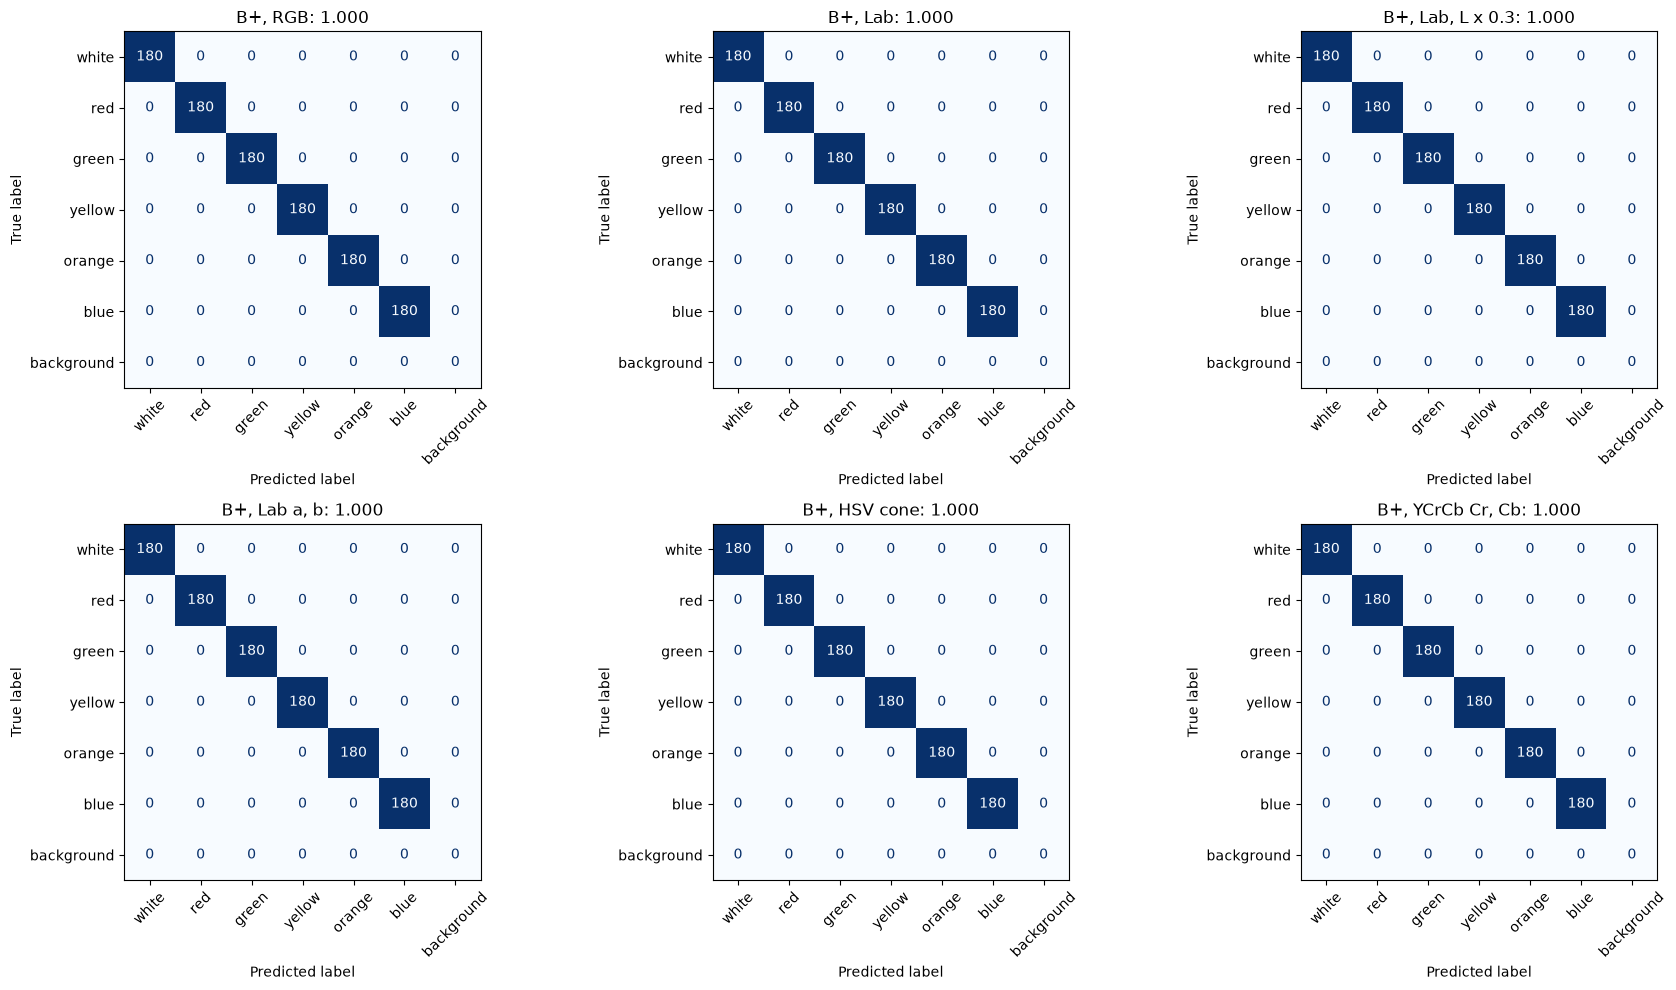

In [ ]:
METHOD = "B+"

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (space, by_method) in zip(axes.flat, states.items(), strict=True):
    by_cube = by_method[METHOD]
    y_true = [c for cube_id in by_cube for c in facelet_colors(truth[cube_id])]
    y_pred = [c for state in by_cube.values() for c in facelet_colors(state)]
    ConfusionMatrixDisplay(
        confusion_matrix(y_true, y_pred, labels=LABELS), display_labels=LABELS
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(f"{METHOD}, {space}: {table.loc[space, METHOD]:.3f}")
plt.tight_layout()

In [ ]:
SPACE = "Lab a, b"

pd.DataFrame(
    {
        name: {cube_id: 54 - correct(state, cube_id) for cube_id, state in by_cube.items()}
        for name, by_cube in states[SPACE].items()
    }
).rename_axis(f"wrong facelets, {SPACE}").loc[lambda errors: errors.sum(axis=1) > 0]

,A,B,B+,B++,C,C+,C++
"wrong facelets, Lab a, b",,,,,,,
cube_0001,1,0,0,0,0,0,0
cube_0003,13,0,0,0,0,0,0
cube_0004,11,0,0,0,0,0,0
cube_0008,4,0,0,0,0,0,0
cube_0009,9,0,0,0,0,0,0
cube_0010,1,0,0,0,0,0,0
cube_0013,14,0,0,0,0,0,0
cube_0014,27,0,0,0,0,0,0
cube_0015,20,0,0,0,0,0,0
